![Banner](../images/09_05_banner_rs_hyperspect.png)


# Reading and Exploring Hyperspectral Data

Hyperspectral products come in many containers: HDF-EOS5 grids and swaths, NetCDF, ENVI binary
files with text headers, one GeoTIFF per band, plain NumPy arrays or folders of PNG images. Each
stores wavelengths, fill values, quality flags and georeferencing in its own way. This notebook
reads all four sensors of the chapter into the same GeoLattice cube, compares orthorectified and swath
products, georeferences a swath from per pixel latitude and longitude and an OHS scene from its
RPCs, explores cubes with band statistics and spectral profiles, and writes subsets to ENVI for
fast reuse.


## Overview

### Containers and layouts

| Format | Typical products | What to look for |
|---|---|---|
| HDF5 / HDF-EOS5 | Tanager, PRISMA, EMIT (NetCDF4 is HDF5 inside) | Groups and datasets; band metadata in attributes; grid georeferencing in `StructMetadata.0` |
| NetCDF | EMIT L1B and L2A | `sensor_band_parameters` (wavelengths, FWHM, good bands) and a `location` group with a geometry lookup table |
| ENVI | AVIRIS-NG, AVIRIS-3, HySpex, many processing chains | A text `.hdr` with `wavelength`, `fwhm`, `bbl` (bad band list), `map info`, `data ignore value`, `reflectance scale factor`; data in BSQ, BIL or BIP |
| GeoTIFF | EnMAP (one multiband file), OHS (one file per band) | Band descriptions or tags for wavelengths; side car XML for gains and band centres |
| Arrays and images | Benchmarks (Pavia), laboratory cameras | Wavelengths come from a separate table or the file names |

Band sequential (BSQ) storage is fast for reading whole bands, BIP for reading whole spectra and
BIL is a compromise. HDF5 files are usually **chunked and compressed**, so reading a window or a
few bands touches only the chunks that hold them.

### Metadata that matters

- **Wavelengths and FWHM** for every band, in nm or µm.
- **Good band flags** (`good_wavelengths` in Tanager and EMIT, `bbl` in ENVI): bands to ignore.
- **Fill values** (often -9999 or 0) and no-data masks.
- **Scale factors and offsets** to turn stored integers into radiance or reflectance.
- **Units**: radiance in W m⁻² sr⁻¹ µm⁻¹ (or µW cm⁻² sr⁻¹ nm⁻¹, a factor of 10 apart), reflectance
  as a fraction or in percent or scaled by 10,000.

### Geometry: swath, grid and RPC

Pushbroom data are acquired as a **swath**: lines along track by samples across track, in sensor
geometry. Three ways bring them to a map:

- an **orthorectified grid** delivered by the provider (Tanager `ortho`, EMIT with its geometry
  lookup table, PRISMA L2D, EnMAP L2A);
- **per pixel latitude and longitude** (Tanager basic, PRISMA L2B and L2C), resampled by the user;
- a **rational polynomial camera (RPC)** model plus a terrain height (OHS, most commercial
  satellites), which maps image coordinates to ground coordinates.

Gridding a swath with nearest neighbour keeps the original spectra unchanged, which matters for
spectral analysis; bilinear or cubic resampling mixes neighbouring spectra.

### Working with large cubes

A full Tanager scene holds about 220 million values. Read only what you need (a window, a bounding
box, a wavelength range or a few bands), keep float32, and write analysis ready subsets to ENVI or
GeoTIFF once instead of reopening the HDF5 file in every step.


## Reading Hyperspectral Data with GeoLattice

GeoLattice has one reader per product family and a dispatcher, `hs.read_hyperspectral`, that picks
the reader from the file. All return a cube `(band, y, x)` (or `(band, line, sample)` for swaths)
with `wavelength`, `fwhm` and `good` coordinates, fill values as NaN and a CRS when known.

### Learning objectives

1. Inspect the structure of an HDF-EOS5 file and find the band metadata.
2. Read Tanager products whole or by window, bounding box, band list or wavelength range, and know
   what each costs.
3. Grid a Tanager swath from its latitude and longitude with `hs.swath_to_grid` and check it
   against the provider's orthorectified product.
4. Read an OHS scene in sensor geometry and orthorectify it with its RPCs.
5. Turn a NumPy array or a folder of images into a cube with `hs.as_cube`.
6. Explore cubes with band statistics, spectral profiles and composites.
7. Write subsets to ENVI and read them back.

### Data

| Dataset | Files |
|---|---|
| Tanager agriculture scene | `Tanger/agriculture/20250224_145149_32_4001/` (ortho SR and radiance) and the basic radiance swath `20250224_145149_32_4001_basic_radiance_hdf5.h5` |
| Tanager swath with a separate geolocation array | `20250516_181930_35_4001_basic_radiance_hdf5.h5` and `20250516_181930_35_4001_geolocation_array.tif` |
| Tanager urban scene | `Tanger/urban/20250423_193451_57_4001/` |
| OHS | `10m_OH2_Hyperspectral_Sample/Spanish-OHS/HAZ2_20180715215912_0002_L1_MSS_CCD1/` |
| Pavia Centre | `Pavia/pavia.npy` |
| HACARUS | `archive/data/<scene>/` |

### Contents

- Setup
- Inside a Tanager HDF-EOS5 file
- Reading Tanager products by subset
- Ortho grid and basic swath
- A swath with a separate geolocation array
- OHS: band files and RPC orthorectification
- Arrays and image folders: Pavia and HACARUS
- Exploring a cube
- Writing and reusing subsets
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import re  # parse wavelengths from file names
import time  # timing
import h5py  # HDF5 files
from PIL import Image  # PNG band images

GeoLattice 0.3.49


## Inside a Tanager HDF-EOS5 file

`h5py` lists every group and dataset. The Tanager surface reflectance file has one grid, `HYP`,
with the cube, its uncertainty and eleven 2-D layers.


In [2]:
sr_agri = tanager_file("agriculture")  # ortho surface reflectance file
with h5py.File(sr_agri, "r") as f:
    rows = []
    f.visititems(lambda name, obj: rows.append({"dataset": name, "shape": obj.shape, "dtype": str(obj.dtype),
                                                "chunks": obj.chunks, "compression": obj.compression})
                 if isinstance(obj, h5py.Dataset) else None)  # one row per dataset
    sr = f["HDFEOS/GRIDS/HYP/Data Fields/surface_reflectance"]  # the cube
    attrs = {k: (v[:4] if np.ndim(v) else v) for k, v in sr.attrs.items()}  # first values of each attribute
    struct = f["HDFEOS INFORMATION/StructMetadata.0"][()].decode()  # grid definition text
print(sr_agri.name, f"{sr_agri.stat().st_size / 2**20:.0f} MB")
display(pd.DataFrame(rows).assign(dataset=lambda d: d["dataset"].str.replace("HDFEOS/GRIDS/HYP/Data Fields/", "")))
attrs

20250224_145149_32_4001_ortho_sr_hdf5.h5 858 MB


,dataset,shape,dtype,chunks,compression
0,aerosol_optical_depth,"(663, 775)",float32,"(42, 97)",gzip
1,beta_cirrus_mask,"(663, 775)",uint8,"(83, 194)",gzip
2,beta_cloud_mask,"(663, 775)",uint8,"(83, 194)",gzip
3,column_water_vapour,"(663, 775)",float32,"(42, 97)",gzip
4,nodata_pixels,"(663, 775)",uint8,"(83, 194)",gzip
5,sensor_azimuth,"(663, 775)",float32,"(42, 97)",gzip
6,sensor_to_ground_path_length,"(663, 775)",float32,"(42, 97)",gzip
7,sensor_zenith,"(663, 775)",float32,"(42, 97)",gzip
8,sun_azimuth,"(663, 775)",float32,"(42, 97)",gzip
9,sun_zenith,"(663, 775)",float32,"(42, 97)",gzip


{'Unit': 'Unitless',
 '_FillValue': np.float32(-9999.0),
 'fwhm': array([5.39, 5.42, 5.45, 5.48], dtype=float32),
 'fwhm_units': 'nm',
 'good_wavelengths': array([1, 1, 1, 1], dtype=uint8),
 'wavelengths': array([376.44, 381.41, 386.38, 391.35], dtype=float32),
 'wavelengths_units': 'nm'}

In [3]:
print("\n".join(line.strip() for line in struct.splitlines()[3:16]))  # grid size, corners and projection

GROUP=GRID_1
GridName="HYP"
Band=426
XDim=775
YDim=663
UpperLeftPointMtrs=(419490.00,7556490.00)
LowerRightMtrs=(442740.00,7536600.00)
Projection=HE5_GCTP_UTM
ZoneCode=-20
SphereCode=12
CompressionType=HE5_HDFE_COMP_DEFLATE
DeflateLevel=4
PixelRegistration=HE5_HDFE_CORNER


The cube is stored band first, `(426, 663, 775)`, as float32 in chunks of 14 bands by 42 by 49
pixels, compressed with gzip. Wavelengths, FWHM and the good band flags are attributes of the
dataset, and `StructMetadata.0` gives the corner coordinates in metres and the UTM zone (`-20`
means zone 20 south). `hs.read_tanager` turns all of this into a cube.


## Reading Tanager products by subset

Because of the chunking, the cost of a read depends on how many chunks it touches. The table times
five ways of reading the same file.


In [4]:
scenes = pd.read_json(TANAGER / "scenes.json")  # scene index with lon/lat bounding boxes
bbox = scenes.loc[scenes["category"] == "Agriculture", "bbox"].iloc[0]  # full scene box
lon0, lat0 = (bbox[0] + bbox[2]) / 2, (bbox[1] + bbox[3]) / 2  # scene centre
small_box = (lon0 - 0.03, lat0 - 0.03, lon0 + 0.03, lat0 + 0.03)  # about 6 x 6 km around it

reads = {
    "whole cube": dict(),
    "window 200 x 200": dict(window=(slice(200, 400), slice(300, 500))),
    "bbox about 6 x 6 km": dict(bbox=small_box),
    "VNIR only (400 to 1000 nm)": dict(wavelength_range=(400, 1000)),
    "three bands": dict(bands=[37, 55, 97]),
}
timing = []
for name, kw in reads.items():
    t0 = time.perf_counter()
    c = hs.read_tanager(sr_agri, **kw)  # read with this subset
    timing.append({"read": name, "shape": c.shape, "MB in memory": round(c.nbytes / 2**20),
                   "seconds": round(time.perf_counter() - t0, 2)})
    if name == "whole cube":
        full = c  # keep the whole cube for later
pd.DataFrame(timing)

,read,shape,MB in memory,seconds
0,whole cube,"(426, 663, 775)",835,3.71
1,window 200 x 200,"(426, 200, 200)",65,0.52
2,bbox about 6 x 6 km,"(426, 222, 207)",75,0.63
3,VNIR only (400 to 1000 nm),"(120, 663, 775)",235,1.15
4,three bands,"(3, 663, 775)",6,0.40


In [5]:
print(full.dims, full.rio.crs, "| x:", float(full.x[0]), "to", float(full.x[-1]), "| y:", float(full.y[0]), "to", float(full.y[-1]))
print("NaN fraction (outside the swath):", round(float(np.isnan(full.isel(band=60)).mean()), 3))
full.coords  # band coordinates: wavelength, fwhm, good

('band', 'y', 'x') EPSG:32720 | x: 419505.0 to 442725.0 | y: 7556475.0 to 7536615.0
NaN fraction (outside the swath): 0.284


Coordinates:
  * band         (band) int64 3kB 0 1 2 3 4 5 6 ... 419 420 421 422 423 424 425
    wavelength   (band) float64 3kB 376.4 381.4 386.4 ... 2.494e+03 2.499e+03
    fwhm         (band) float64 3kB 5.39 5.42 5.45 5.48 ... 5.21 5.21 5.2 5.2
    good         (band) bool 426B True True True True ... True True True True
  * y            (y) float64 5kB 7.556e+06 7.556e+06 ... 7.537e+06 7.537e+06
  * x            (x) float64 6kB 4.195e+05 4.195e+05 ... 4.427e+05 4.427e+05
    spatial_ref  int64 8B 0

Reading the whole cube decompresses every chunk and takes a few seconds; a window, a bounding box or
a few bands is much faster and smaller. The VNIR read still touches every pixel and so costs about
as much as its share of the bands. Pixels outside the tilted swath are NaN: the orthorectified grid
is a rectangle around a rotated footprint, so about a quarter of it is empty.


## Ortho grid and basic swath

The basic product is the same acquisition before orthorectification: lines and samples in sensor
geometry, with latitude and longitude for every pixel. `hs.swath_to_grid` places each grid cell on
the nearest swath pixel; with a 30 m grid aligned to multiples of 30 m it lands on the same cells
as Planet's ortho product, so the two can be compared pixel by pixel.


In [6]:
basic = DATA / "20250224_145149_32_4001_basic_radiance_hdf5.h5"  # swath radiance
sw = hs.read_hyperspectral(basic, wavelength_range=(840, 880))  # dispatcher picks read_tanager
print(sw.dims, sw.shape, "| lat:", round(float(sw.lat.min()), 3), "to", round(float(sw.lat.max()), 3))
grid = hs.swath_to_grid(sw, 30.0)  # nearest-neighbour gridding to UTM, 30 m
ortho = hs.read_tanager(tanager_file("agriculture", "radiance"), wavelength_range=(840, 880))  # provider grid
print("gridded:", grid.shape, grid.rio.crs, "| ortho:", ortho.shape, ortho.rio.crs)

('band', 'line', 'sample') (8, 501, 607) | lat: -22.275 to -22.095


gridded: (8, 663, 774) EPSG:32720 | ortho: (8, 663, 775) EPSG:32720


common cells: 368,045 | identical values: 98.9% | correlation: 0.9989


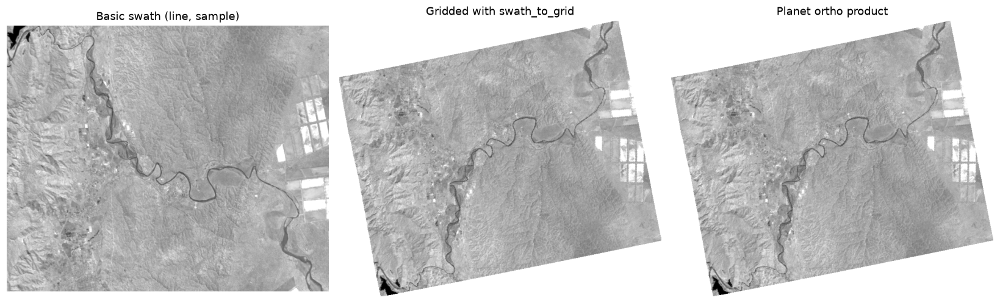

In [7]:
a, b = grid.isel(band=4), ortho.isel(band=4)  # one NIR band (about 861 nm) from each
common_x = np.intersect1d(a.x.values, b.x.values)  # shared grid columns
common_y = np.intersect1d(a.y.values, b.y.values)  # shared grid rows
A = a.sel(x=common_x, y=common_y).values  # gridded swath on the common cells
B = b.sel(x=common_x, y=common_y).values  # ortho product on the same cells
ok = np.isfinite(A) & np.isfinite(B)  # cells valid in both
print(f"common cells: {ok.sum():,} | identical values: {np.mean(np.isclose(A[ok], B[ok])):.1%} | "
      f"correlation: {np.corrcoef(A[ok], B[ok])[0, 1]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
axes[0].imshow(sw.isel(band=4), cmap="gray", vmax=np.nanpercentile(sw.isel(band=4), 99))
axes[0].set_title("Basic swath (line, sample)")
for ax, img, t in [(axes[1], A, "Gridded with swath_to_grid"), (axes[2], B, "Planet ortho product")]:
    ax.imshow(img, cmap="gray", vmax=np.nanpercentile(B, 99)); ax.set_title(t)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The swath is the image as the sensor saw it, unrotated. After gridding, most cells hold exactly the
value of Planet's ortho product and the correlation is close to one; the rest differ because the
two nearest neighbour searches break ties differently near the swath edges and Planet's processor
uses its own terrain model. Gridding your own swath therefore reproduces the provider's grid, which
is useful when only the basic product is available or when a different grid is needed.


## A swath with a separate geolocation array

The second basic scene in the chapter folder ships its latitude and longitude as a two band GeoTIFF
instead. `read_tanager(geolocation=...)` attaches them.


(3, 624, 607) | centre: 40.134 -104.52


gridded: (3, 811, 862) EPSG:32613


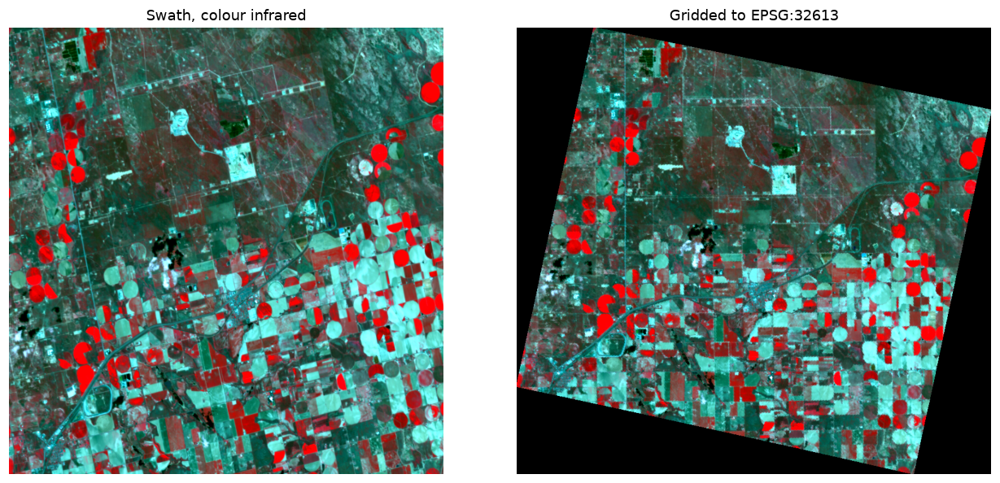

In [8]:
sw2 = hs.read_tanager(DATA / "20250516_181930_35_4001_basic_radiance_hdf5.h5",
                      geolocation=DATA / "20250516_181930_35_4001_geolocation_array.tif",
                      bands=[37, 55, 97])  # about 561, 651 and 861 nm
print(sw2.shape, "| centre:", round(float(sw2.lat.mean()), 3), round(float(sw2.lon.mean()), 3))
g2 = hs.swath_to_grid(sw2, 30.0)  # UTM grid of the scene centre
print("gridded:", g2.shape, g2.rio.crs)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
hs.plot_rgb(sw2, (861, 651, 561), ax=axes[0], title="Swath, colour infrared")
hs.plot_rgb(g2, (861, 651, 561), ax=axes[1], title=f"Gridded to {g2.rio.crs}")
plt.tight_layout()
plt.show()

This acquisition lies on the Colorado plains east of the Front Range (about 40.1° N, 104.5° W): irrigated
circles and rectangular fields stand out in colour infrared. Gridding rotates the swath into its
north up footprint.


## OHS: band files and RPC orthorectification

An OHS L1 scene is 32 single band GeoTIFFs of 5056 by 5056 pixels with a shared RPC model and
a `*_meta.xml`. `hs.read_ohs` stacks the bands in order, attaches the nominal band centres and
keeps the RPCs; `window=` reads a part of the image and `ortho=True` warps it to a map.


In [9]:
ohs_dir = next((DATA / "10m_OH2_Hyperspectral_Sample/Spanish-OHS").iterdir())  # scene folder
WIN_OHS = (slice(2000, 2600), slice(2000, 2600))  # 600 x 600 pixels (6 x 6 km)
ohs = hs.read_ohs(ohs_dir, window=WIN_OHS)  # sensor geometry, all 32 bands
print(ohs.dims, ohs.shape, "| wavelengths:", hs.wavelengths(ohs)[[0, -1]])
print({k: v for k, v in ohs.attrs.items() if k != "rpcs"})
rpc = ohs.attrs["rpcs"]  # rational polynomial camera model (shifted to the window)
print("RPC offsets: line", rpc.line_off, "sample", rpc.samp_off, "| lat", rpc.lat_off, "lon", rpc.long_off,
      "| height", rpc.height_off, "m")

('band', 'line', 'sample') (32, 600, 600) | wavelengths: [466. 940.]
{'sensor': 'OHS', 'SatelliteID': 'ovs-2', 'Sensor': 'CMOSMSS', 'ProductLevel': 'L1', 'CenterTime': '2018-7-14T11:38:31.092777', 'TimeType': 'BJT', 'CloudPercent': '0', 'ImageRowGSD': '10', 'CenterLatitude': '38.960490', 'CenterLongitude': '-5.320217', 'PixelInvalidVal': '0'}
RPC offsets: line 2073.0 sample 528.0 | lat 38.9573957 lon -5.31835922 | height 583.0 m


(32, 756, 765) EPSG:32630 | valid: 0.69


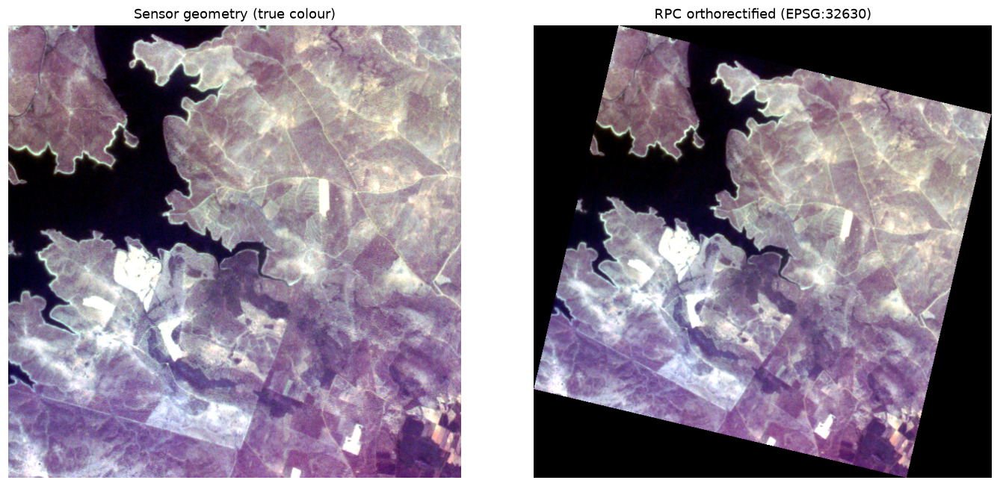

In [10]:
ohs_ortho = hs.read_ohs(ohs_dir, window=WIN_OHS, ortho=True)  # RPC warp to UTM at 10 m
print(ohs_ortho.shape, ohs_ortho.rio.crs, "| valid:", round(float(np.isfinite(ohs_ortho.isel(band=0)).mean()), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
hs.plot_rgb(ohs, (656, 566, 480), ax=axes[0], title="Sensor geometry (true colour)")
hs.plot_rgb(ohs_ortho, (656, 566, 480), ax=axes[1], title=f"RPC orthorectified ({ohs_ortho.rio.crs})")
plt.tight_layout()
plt.show()

The L1 image is already close to north up, so the RPC warp mainly rotates it by a few degrees,
corrects the scale and places it on a UTM grid (zone 30 N) with real coordinates. The window shows
the shore of a reservoir (dark water) surrounded by dry summer fields and pasture. The NaN corners of the ortho grid are outside the rotated window.
Note that the values are L1 digital numbers, not radiance or reflectance.


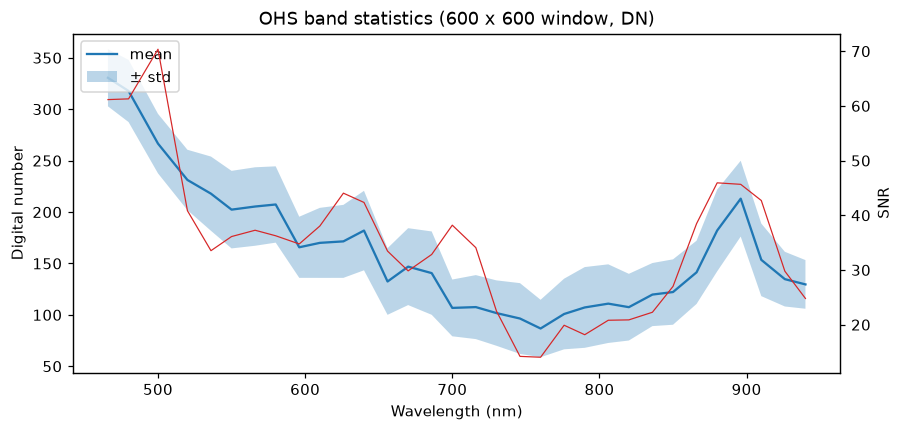

In [11]:
st_ohs = hs.band_stats(ohs)  # per band statistics of the raw DNs
ax = hs.plot_band_stats(st_ohs)
ax.set_ylabel("Digital number"); ax.set_title("OHS band statistics (600 x 600 window, DN)")
plt.show()

## Arrays and image folders: Pavia and HACARUS

Benchmarks are often distributed as arrays without metadata. `hs.as_cube` adds the band axis and
wavelengths. The Pavia Centre array is `(rows, cols, bands)`, so it is transposed first; its 102
ROSIS bands span about 430 to 860 nm and are treated as evenly spaced.


(102, 1096, 715) | reflectance range: 0.0 to 0.8


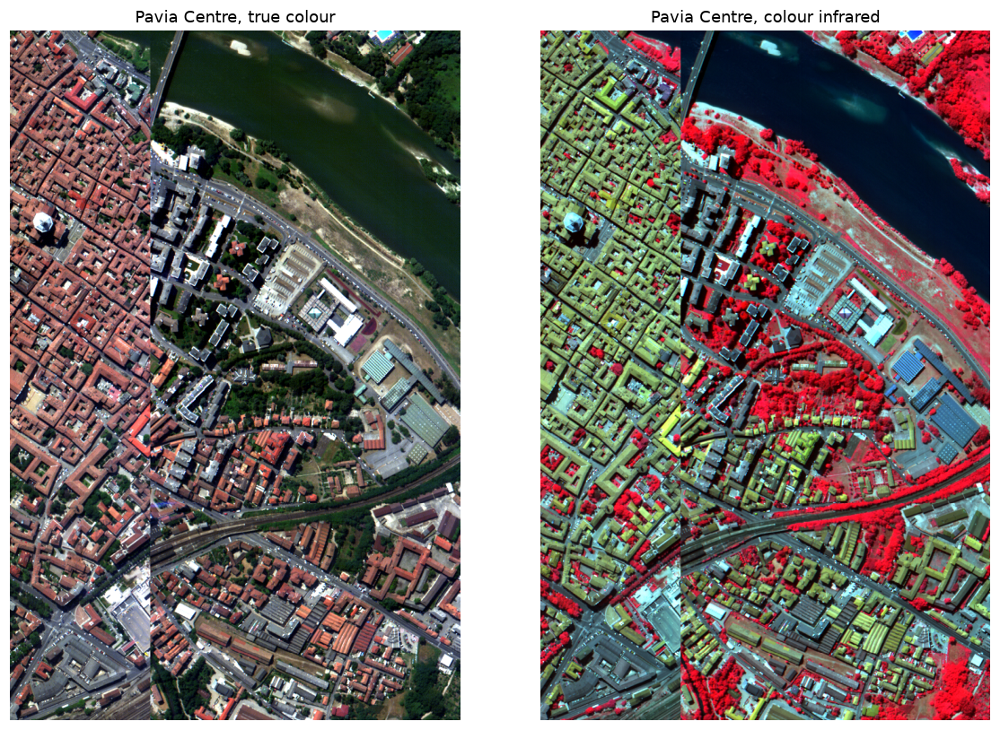

In [12]:
arr = np.load(DATA / "Pavia/pavia.npy")  # (1096, 715, 102) uint16
pavia = hs.as_cube(arr.transpose(2, 0, 1).astype("float32") / 10000, np.linspace(430, 860, arr.shape[2]))
print(pavia.shape, "| reflectance range:", float(pavia.min()), "to", round(float(pavia.max()), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 7.5))
hs.plot_rgb(pavia, (640, 550, 460), ax=axes[0], title="Pavia Centre, true colour")
hs.plot_rgb(pavia, "color_infrared", ax=axes[1], title="Pavia Centre, colour infrared")
plt.tight_layout()
plt.show()

Pavia Centre is a 1.3 m ROSIS image of the historic centre of Pavia and the Ticino river. The
vertical seam about a third of the way across is where the dataset authors removed a strip of
pixels without information and joined the two parts.
Dividing by 10,000 gives reflectance assuming the common scaling of this benchmark.


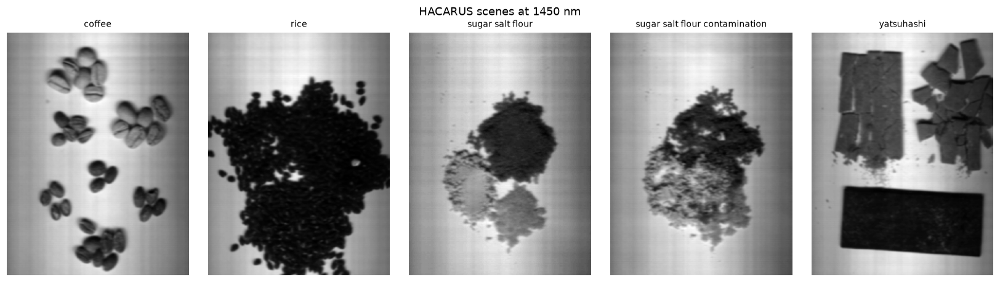

In [13]:
def read_png_cube(folder):
    """Stack the *_<wavelength>nm.png band images of a HACARUS scene into a cube."""
    files = sorted(Path(folder).glob("*nm.png"), key=lambda p: float(re.search(r"_(\d+)nm", p.name)[1]))
    wl = [float(re.search(r"_(\d+)nm", p.name)[1]) for p in files]  # wavelength from the file name
    stack = np.stack([np.asarray(Image.open(p), dtype="float32") for p in files])  # (band, row, col)
    return hs.as_cube(stack, wl, name="dn")


lab = {p.name: read_png_cube(p) for p in sorted((DATA / "archive/data").iterdir())}  # all five scenes
fig, axes = plt.subplots(1, 5, figsize=(15, 4.2))
for ax, (name, c) in zip(axes, lab.items()):
    ax.imshow(hs.band_at(c, 1450), cmap="gray")  # 1450 nm, a water and O-H band
    ax.set_title(name.replace("_", " "), fontsize=9); ax.axis("off")
plt.suptitle("HACARUS scenes at 1450 nm")
plt.tight_layout()
plt.show()

## Exploring a cube

The urban scene (Portland, Oregon) mixes many materials. A 300 by 300 pixel window is centred on
the open water pixel nearest the scene centre, so it holds a stretch of river and the surrounding
city; it is read with all bands, then explored with band statistics, composites and
spectral profiles.


window rows 319 to 619 | cols 285 to 585
(368, 300, 300)


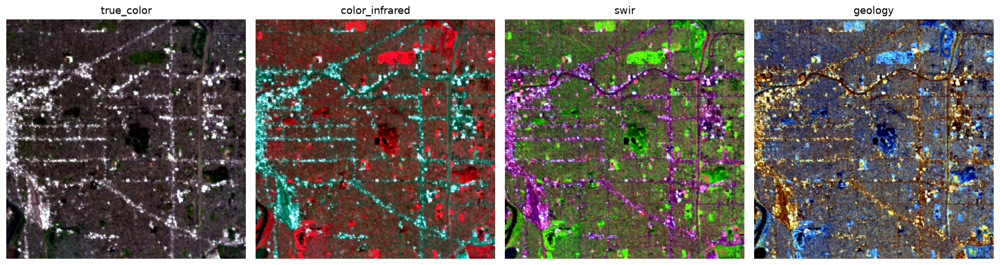

In [14]:
few = hs.read_tanager(tanager_file("urban"), bands=[37, 97])  # green and NIR of the whole scene
g, n = few.values  # 561 and 861 nm
water = (g - n) / (g + n) > 0.3  # open water by NDWI
rr, cc = np.nonzero(water)  # water pixels
i = np.argmin((rr - water.shape[0] / 2) ** 2 + (cc - water.shape[1] / 2) ** 2)  # water pixel nearest the centre
r0, c0 = int(np.clip(rr[i] - 150, 0, water.shape[0] - 300)), int(np.clip(cc[i] - 150, 0, water.shape[1] - 300))
urban = hs.read_tanager(tanager_file("urban"), window=(slice(r0, r0 + 300), slice(c0, c0 + 300)))  # 9 x 9 km
print("window rows", r0, "to", r0 + 300, "| cols", c0, "to", c0 + 300)
urban = urban.isel(band=np.flatnonzero(urban["good"].values))  # drop the product's bad bands
print(urban.shape)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, comp in zip(axes, ["true_color", "color_infrared", "swir", "geology"]):
    hs.plot_rgb(urban, comp, ax=ax)  # four standard composites
plt.tight_layout()
plt.show()

,mean,std,snr
mean,0.138,0.041,6.080
min,0.022,0.012,2.556
max,0.246,0.063,8.435


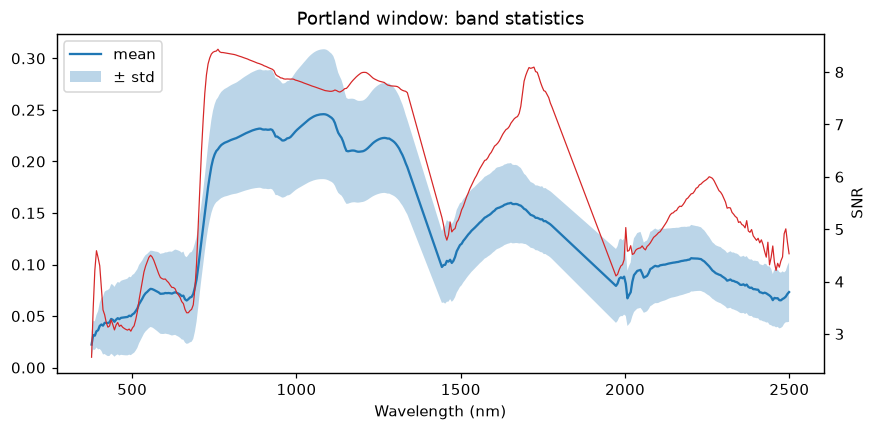

In [15]:
st = hs.band_stats(urban)  # mean, std, min, max, NaN fraction and SNR per band
display(st.describe().loc[["mean", "min", "max"], ["mean", "std", "snr"]].round(3))
ax = hs.plot_band_stats(st)
ax.set_title("Portland window: band statistics")
plt.show()

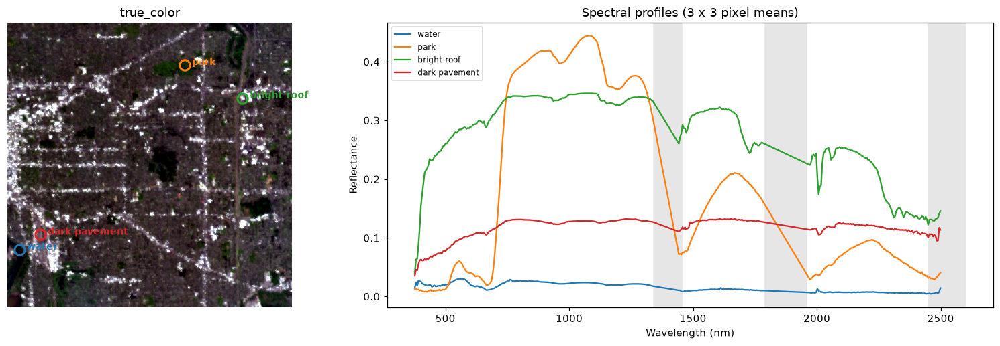

In [16]:
xs, ys = urban.x.values, urban.y.values  # map coordinates of the window
G, R, N, S1 = (hs.band_at(urban, w).values for w in (560, 650, 860, 1650))  # four bands
ndvi, ndwi = (N - R) / (N + R), (G - N) / (G + N)  # vegetation and water indices


def pick(score, q):
    """(row, col) of the pixel whose score is closest to its q-th quantile."""
    return np.unravel_index(np.nanargmin(np.abs(score - np.nanquantile(score, q))), score.shape)


pts = {"water": pick(np.where(ndwi > 0.3, N, np.nan), 0.5),  # typical open water pixel
       "park": pick(ndvi, 0.99),  # dense vegetation
       "bright roof": pick(np.where(ndvi < 0.1, S1, np.nan), 0.99),  # brightest non-vegetated SWIR
       "dark pavement": pick(np.where((ndvi < 0.1) & (ndwi < 0), S1, np.nan), 0.1)}  # dark, dry, bare
frame = hs.spectra_at(urban, [(xs[c], ys[r]) for r, c in pts.values()], buffer=1)  # 3 x 3 means
frame.index = list(pts)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.8]})
hs.plot_rgb(urban, "true_color", ax=axes[0])
for (k, (r, c)), col in zip(pts.items(), ["C0", "C1", "C2", "C3"]):
    axes[0].plot(c, r, "o", mfc="none", mec=col, ms=10, mew=2)
    axes[0].text(c + 8, r, k, color=col, fontsize=9, weight="bold")
hs.plot_spectra(frame, ax=axes[1], bad_ranges=hs.preprocess.WATER_VAPOUR_RANGES)
axes[1].set_title("Spectral profiles (3 x 3 pixel means)")
plt.tight_layout()
plt.show()

The four pixels are chosen by simple index rules, as in notebook 09_05_00. Water is dark at all
wavelengths and nearly zero beyond 900 nm; the park has the vegetation red edge; the bright roof and
the dark pavement are flat spectra that differ mainly in brightness, with small SWIR features that
come from roofing materials and asphalt.


In [17]:
fig = hs.spectral_viewer(urban.isel(x=slice(None, None, 3), y=slice(None, None, 3)),
                         [(xs[c], ys[r]) for r, c in pts.values()], composite="true_color")
fig.update_layout(width=950, height=420)
fig.show()

## Writing and reusing subsets

ENVI is the simplest interchange format for cubes: a raw binary file plus a text header that
keeps wavelengths, FWHM, the bad band list and the map information. `hs.write_envi` writes a cube,
`hs.read_envi` reads it back (also by window and bands through a memory map), and
`hs.subset_file` cuts a smaller file out of a large one without loading it.


In [18]:
path = hs.write_envi(urban, OUT / "portland_tanager_sr.img")  # BSQ float32 + .hdr
size = Path(path).stat().st_size / 2**20  # data file size
back = hs.read_envi(path)  # read it again
print(path, f"{size:.0f} MB", "| same values:", bool(np.allclose(back.values, urban.values, equal_nan=True)),
      "| CRS:", back.rio.crs, "| wavelengths kept:", bool(np.allclose(hs.wavelengths(back), hs.wavelengths(urban))))
print(Path(path + ".hdr").read_text()[:600])

outputs/portland_tanager_sr.img 126 MB | same values: True | CRS: EPSG:32610 | wavelengths kept: True
ENVI
description = {geolattice.rsense.hyperspectral}
samples = 300
lines = 300
bands = 368
header offset = 0
file type = ENVI Standard
data type = 4
interleave = bsq
byte order = 0
data ignore value = -9999
wavelength units = Nanometers
wavelength = {376.4400, 381.4100, 386.3800, 391.3500, 396.3200, 401.2900, 406.2600, 411.2300, 416.2100, 421.1800, 426.1600, 431.1400, 436.1200, 441.1000, 446.0800, 451.0600, 456.0400, 461.0200, 466.0100, 470.9900, 475.9800, 480.9600, 485.9500, 490.9300, 495.9200, 500.9100, 505.9000, 510.8900, 515.8800, 520.8700, 525.8700, 530.8600, 535.8500, 540.8500, 545.8400,


In [19]:
t0 = time.perf_counter()
part = hs.read_envi(path, window=(slice(0, 50), slice(0, 50)), bands=range(0, urban.sizes["band"], 10))
print("memory-mapped subset:", part.shape, f"in {time.perf_counter() - t0:.3f} s")
small = hs.subset_file(path, OUT / "clips/portland_100px.img", window=(slice(100, 200), slice(100, 200)))
print("subset file:", small, hs.read_envi(small).shape)

memory-mapped subset: (37, 50, 50) in 0.007 s
subset file: outputs/clips/portland_100px.img (368, 100, 100)


Writing once and reading the ENVI file later avoids decompressing the HDF5 file again: the memory
mapped read above takes milliseconds. Later notebooks read their own windows straight from the
Tanager files so that each runs on its own, but in a project you would cut analysis ready subsets
like these first.


## Summary and exercises

**Key points**

- Hyperspectral containers differ (HDF-EOS5, NetCDF, ENVI, GeoTIFF, arrays, images) but carry the
  same essentials: wavelengths, FWHM, good bands, fill values, scale factors and georeferencing.
- HDF5 chunking makes windows, bounding boxes and band subsets cheap; whole cube reads are not.
- Swaths are in sensor geometry. Nearest neighbour gridding from per pixel latitude and longitude
  (`hs.swath_to_grid`) reproduces the provider's 30 m grid for Tanager; RPCs orthorectify OHS.
- `hs.as_cube` turns any array into a GeoLattice cube once the wavelengths are known.
- Band statistics, composites and spectral profiles are the first look at any cube; ENVI files make
  subsets fast to reuse.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `read_hyperspectral`,
`swath_to_grid`, `read_ohs`, `as_cube`, `band_at`, `wavelengths`, `band_stats`, `plot_band_stats`,
`plot_rgb`, `spectra_at`, `plot_spectra`, `spectral_viewer`, `write_envi`, `read_envi`,
`subset_file`.

**Exercises**

1. Time a read of the snow and ice scene with `wavelength_range=(2000, 2400)` and with
   `bands=` set to every tenth band. Which is faster, and why?
2. Grid the agriculture swath at 60 m with `swath_to_grid(sw, 60.0)` and compare it with the 30 m
   ortho product aggregated to 60 m (`coarsen(x=2, y=2).mean()`).
3. Orthorectify the OHS window with `crs="EPSG:4326"` and a resolution of 0.0001°. How many pixels
   does the result have, and why is it not square?
4. Write the Portland window as BIP with `write_envi(..., interleave="bip")` and time reading one
   full spectrum and one full band from the BSQ and BIP files.
